# Aula 2 — Regressão Supervisionada
**Datasets:**

1.   Auto MPG (consumo de carros)
2.   California Housing (preço de casas)

In [24]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error
from sklearn.datasets import fetch_california_housing

sns.set_theme(style="whitegrid")

# Dataset 1 — Auto MPG

In [2]:
df = sns.load_dataset('mpg')
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [6]:
df.shape

(398, 9)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [4]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


### Limpeza: nulos e duplicados

In [5]:
print("Nulos por coluna:")
print(df.isnull().sum())
print("\nDuplicados:", df.duplicated().sum())

Nulos por coluna:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

Duplicados: 0


Só `horsepower` tem nulos (6 carros, ~1,5% dos dados). Opções:
- **Remover as linhas** — simples, perde pouca informação;
- **Imputar** (ex.: mediana) — útil quando há muitos nulos.

In [7]:
df = df.drop_duplicates().dropna()
print("Formato após limpeza:", df.shape)

Formato após limpeza: (392, 9)


# **Análise Exploratória de Dados**

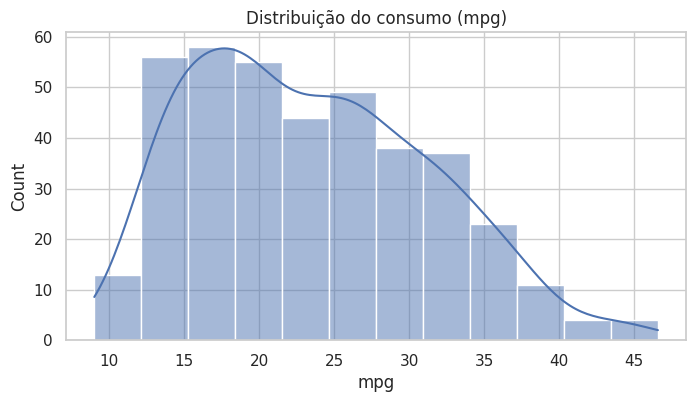

In [9]:
# 1. Distribuição do alvo
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="mpg", kde=True)
plt.title("Distribuição do consumo (mpg)")
plt.show()

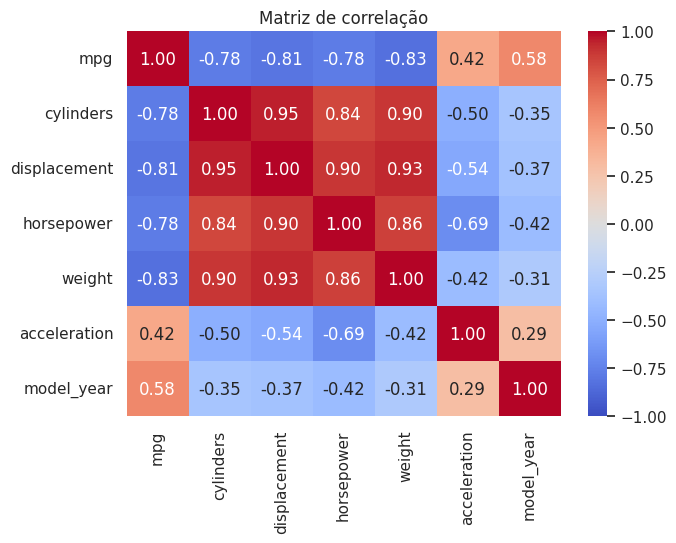

,mpg
weight,-0.832244
displacement,-0.805127
horsepower,-0.778427
cylinders,-0.777618
acceleration,0.423329
model_year,0.580541


In [10]:
# 2. Correlação de cada feature numérica com o alvo
corr = df.corr(numeric_only=True)

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de correlação")
plt.show()

corr["mpg"].drop("mpg").sort_values()

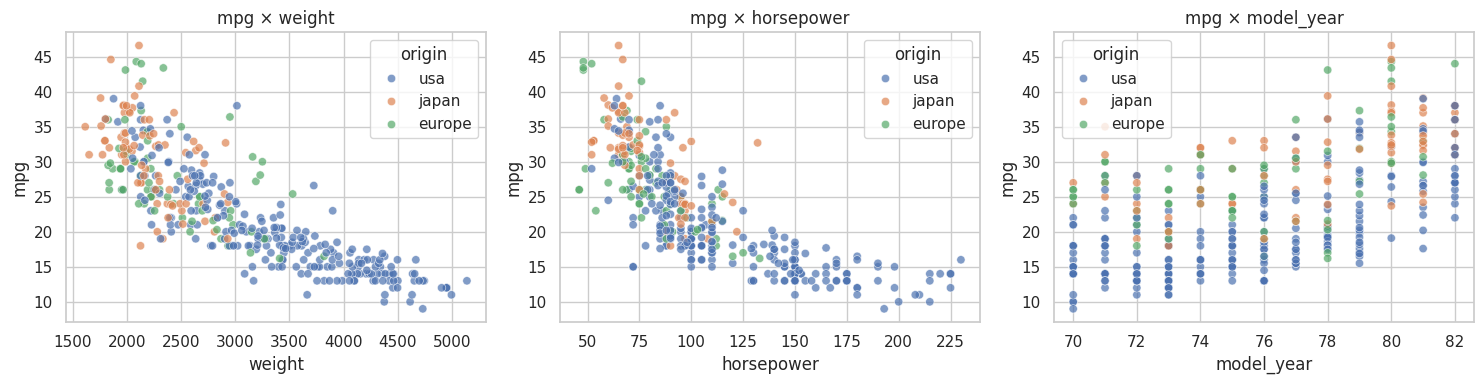

In [11]:
# 3. Relação de algumas features com o alvo
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["weight", "horsepower", "model_year"]):
    sns.scatterplot(data=df, x=col, y="mpg", hue="origin", alpha=0.7, ax=ax)
    ax.set_title(f"mpg × {col}")
plt.tight_layout()
plt.show()

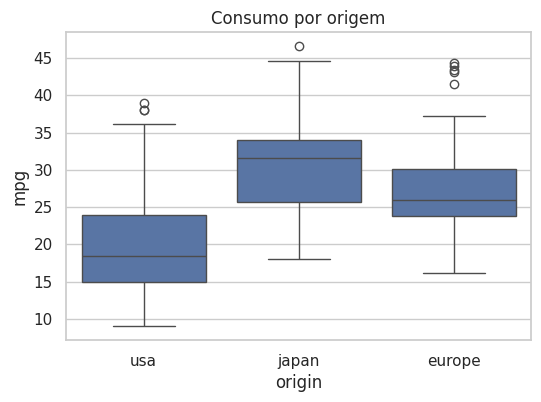

In [12]:
# 4. Feature categórica × alvo
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="origin", y="mpg")
plt.title("Consumo por origem")
plt.show()

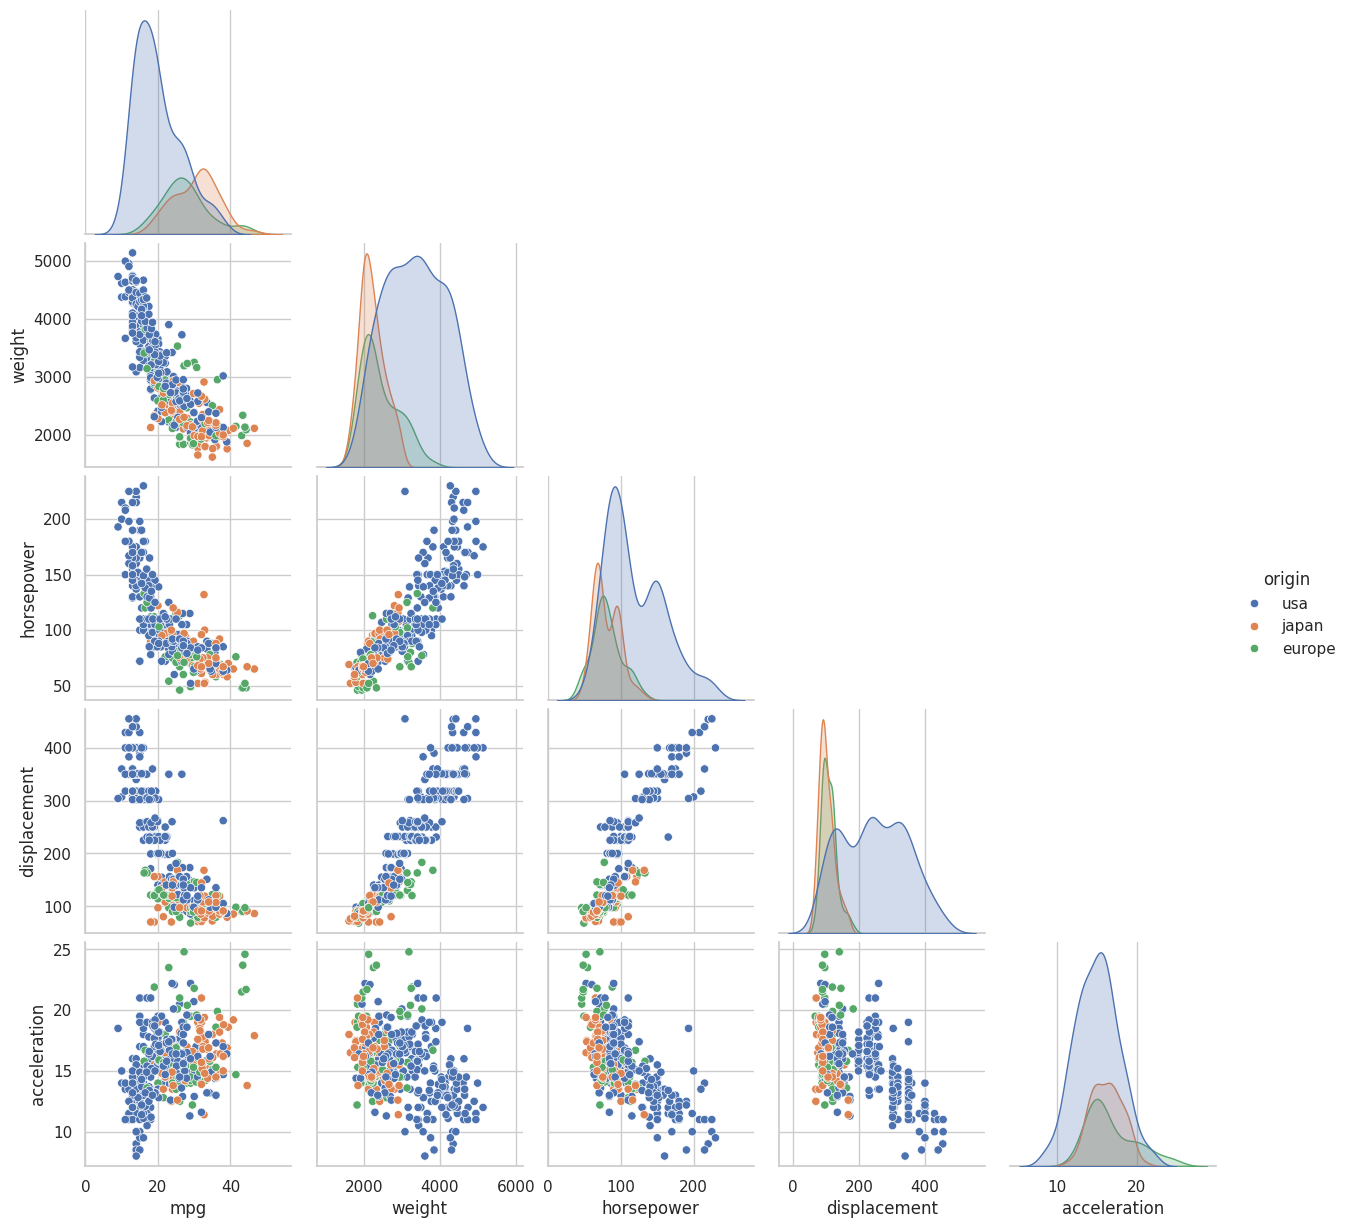

In [13]:
# 5. Visão geral (pode demorar um pouco)
sns.pairplot(df[["mpg", "weight", "horsepower", "displacement", "acceleration", "origin"]],
             hue="origin", corner=True)
plt.show()

#**Separação dos Dados** (Treino/Teste)


In [14]:
X = df[['weight']]
y = df['mpg']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [33]:
def avaliar(nome, y_real, y_prev):
  return {
      "modelo": nome,
      "MAE":  mean_absolute_error(y_real, y_prev),
      "RMSE": root_mean_squared_error(y_real, y_prev),
      "R²":   r2_score(y_real, y_prev),
  }

## Primeiro modelo: o baseline (`DummyRegressor`)

In [15]:
baseline = DummyRegressor(strategy='mean')

baseline.fit(X_train, y_train)

y_predict_base = baseline.predict(X_test)

print(y_predict_base[:5])
print(f"Media de treino: {y_train.mean()}")

[23.59936102 23.59936102 23.59936102 23.59936102 23.59936102]
Media de treino: 23.599361022364217


## Modelo: Regressão Linear (`LinearRegression`)

In [18]:
model_liner = LinearRegression()

model_liner.fit(X_train, y_train)

print(f"Coef: {model_liner.coef_[0]}")
print(f"Inter: {model_liner.intercept_}")

Coef: -0.007903610385225605
Inter: 47.200526427552106


In [19]:
y_predict_linear = model_liner.predict(X_test)

df_resultado = pd.DataFrame({
    'Real': y_test.values[:5],
    'Predito': y_predict_linear[:5]
})

print(df_resultado)


   Real    Predito
0  26.0  29.899523
1  21.6  25.109935
2  36.1  32.974028
3  26.0  31.748968
4  27.0  25.149453


In [22]:
mae = mean_absolute_error(y_test, y_predict_linear)
print(f"Lienar MAE: {mae:.2f} MPG")

mae_base_line = mean_absolute_error(y_test, y_predict_base)
print(f"Baseline MAE: {mae:.2f} MPG")

Lienar MAE: 3.46 MPG
Baseline MAE: 3.46 MPG


In [27]:
mse =  mean_squared_error(y_test, y_predict_linear)
print(f"Lienar MSE: {mse:.2f} MPG")

rmse =  root_mean_squared_error(y_test, y_predict_linear)
print(f"Lienar RMSE: {rmse:.2f} MPG")

mse_base =  mean_squared_error(y_test, y_predict_base)
print(f"Base MSE: {mse_base:.2f} MPG")

rmse_base =  root_mean_squared_error(y_test, y_predict_base)
print(f"Base RMSE: {rmse_base:.2f} MPG")

Lienar MSE: 17.69 MPG
Lienar RMSE: 4.21 MPG
Base MSE: 51.62 MPG
Base RMSE: 7.18 MPG


In [31]:
r2 =  r2_score(y_test, y_predict_linear)
print(f"Base R2: {r2:.2f} MPG")

r2_base =  r2_score(y_test, y_predict_base)
print(f"Base R2: {r2_base:.2f} MPG")

Base R2: 0.65 MPG
Base R2: -0.01 MPG


In [34]:
resultados = pd.DataFrame([
    avaliar("Baseline", y_test, y_predict_base),
    avaliar("Linear (weight)", y_test, y_predict_linear),
])
print(resultados.round(2))

            modelo   MAE  RMSE    R²
0         Baseline  5.88  7.18 -0.01
1  Linear (weight)  3.46  4.21  0.65


In [48]:
def show(y_real, y_predict):
  plt.figure(figsize=(6, 4))
  plt.scatter(y_real, y_predict, alpha=0.7, color='#2563eb')
  plt.plot([y_real.min(), y_real.max()],
            [y_real.min(), y_real.max()], '--r', lw=2)
  plt.xlabel('Valores Reais (MPG)')
  plt.ylabel('Valores Preditos (MPG)')
  plt.show()


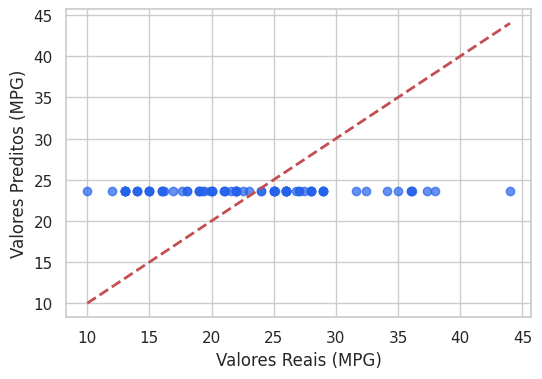

In [49]:
show(y_test, y_predict_base)

In [50]:
housing = fetch_california_housing(as_frame=True)

df_house = housing.frame

df_house.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [52]:
X = df_house.drop(columns=['MedHouseVal'])
y = df_house['MedHouseVal']

X_train, X_test, y_train, y_test,   train_test_split(X, y, test_size=0.2, random_state=42)

baseline_h = DummyRegressor(strategy='mean')
baseline_h.fit(X_train, y_train)

y_predict_base_h =  baseline.predict(X_test)

print(avaliar("Baseline", y_test, y_predict_base_h))

{'modelo': 'Baseline', 'MAE': 5.880956039956324, 'RMSE': 7.184726327203216, 'R²': -0.011357808240890499}


In [75]:
def treino_vs_teste(nome, modelo):
  modelo.fit(X_train, y_train)
  r2_tr = r2_score(y_train,    modelo.predict(X_train))
  r2_te = r2_score(y_test, modelo.predict(X_test))
  print(f"{nome:<18} treino={r2_tr:.2f} "
        f"teste={r2_te:.2f} gap={r2_tr - r2_te:.2f}")

treino_vs_teste("Linear", LinearRegression())
treino_vs_teste("Árvore depth=3",DecisionTreeRegressor(max_depth=3))
treino_vs_teste("Árvore sem limite",DecisionTreeRegressor())


Linear             treino=0.70 teste=0.65 gap=0.04
Árvore depth=3     treino=0.75 teste=0.67 gap=0.08
Árvore sem limite  treino=0.97 teste=0.35 gap=0.63


In [76]:
scaler  =  StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [77]:
modelo_ridge = Ridge(alpha=1.0)
modelo_ridge.fit(X_train_scaled, y_train)

y_pred_ridge = modelo_ridge.predict(X_test_scaled)
print(avaliar("Ridge", y_test, y_pred_ridge))


{'modelo': 'Ridge', 'MAE': 3.2649148085944053, 'RMSE': 4.062637277121519, 'R²': 0.6766294466524424}


In [78]:
# Lasso: penalidade L1 (soma dos |coeficientes|)
modelo_lasso = Lasso(alpha=0.1)
modelo_lasso.fit(X_train_scaled, y_train)

y_pred_lasso = modelo_lasso.predict(X_test_scaled)
print(avaliar("Lasso", y_test, y_pred_lasso))


{'modelo': 'Lasso', 'MAE': 3.249683836093425, 'RMSE': 4.050682374816375, 'R²': 0.67852977650082}


In [79]:
# 5 folds, embaralhando antes de dividir
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Pipeline: o scaler é ajustado DENTRO de cada fold
modelo = make_pipeline(StandardScaler(),
                       Ridge(alpha=1.0))

scores = cross_val_score(modelo, X_train, y_train, cv=kfold, scoring='r2')

print("R² por fold:", scores.round(3))
print(f"R² médio: {scores.mean():.3f}"
      f" ± {scores.std():.3f}")


R² por fold: [0.607 0.764 0.711 0.722 0.655]
R² médio: 0.692 ± 0.055


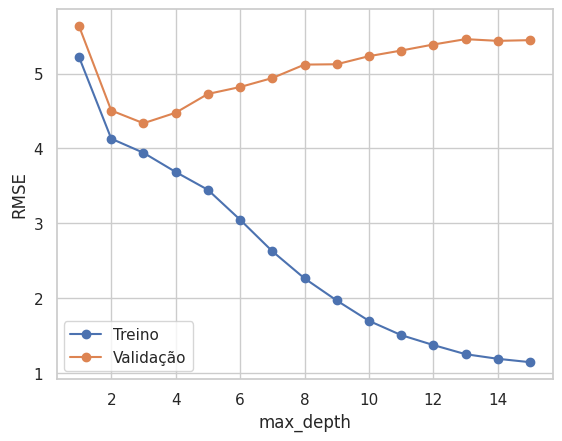

In [81]:
from sklearn.model_selection import cross_validate


profundidades = range(1, 16)
treino, validacao = [], []

for d in profundidades:
    cv = cross_validate(
        DecisionTreeRegressor(max_depth=d, random_state=42),
        X_train, y_train, cv=kfold,
        scoring='neg_root_mean_squared_error',
        return_train_score=True)
    treino.append(-cv['train_score'].mean())
    validacao.append(-cv['test_score'].mean())

plt.plot(profundidades, treino, 'o-', label='Treino')
plt.plot(profundidades, validacao, 'o-', label='Validação')
plt.xlabel('max_depth'); plt.ylabel('RMSE')
plt.legend(); plt.show()


In [88]:
def pipe(modelo):
    return make_pipeline(StandardScaler(), modelo)

modelos = {
    "Baseline": DummyRegressor(),
    "Linear":   pipe(LinearRegression()),
    "Ridge":    pipe(Ridge(alpha=1.0)),
    "Lasso":    pipe(Lasso(alpha=0.00001)),
    "Tree":     pipe(DecisionTreeRegressor(max_depth=3)),
}

for nome, modelo in modelos.items():
    scores = cross_val_score(modelo, X_train, y_train, cv=kfold,scoring='neg_root_mean_squared_error')
    rmse = -scores  # sklearn devolve o RMSE negativo
    print(f"{nome:<9} RMSE = {rmse.mean():.3f}"
          f" ± {rmse.std():.3f}")


Baseline  RMSE = 7.914 ± 0.782
Linear    RMSE = 4.365 ± 0.537
Ridge     RMSE = 4.364 ± 0.540
Lasso     RMSE = 4.365 ± 0.537
Tree      RMSE = 4.336 ± 0.503
